# Load soil moisture data #

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, models, expts
from cdrmip_extremes import load_esgf, utils, load_data

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/44755/status,
Dashboard: /proxy/44755/status,Workers: 28
Total threads: 28,Total memory: 0 B
Status: running,Using processes: True
Comm: tcp://127.0.0.1:32969,Workers: 0
Dashboard: /proxy/44755/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45849,Total threads: 1
Dashboard: /proxy/43801/status,Memory: 0 B
Nanny: tcp://127.0.0.1:37087,


## Load Data ##

In [3]:
# save
save_dir = os.path.join(data_dir,'raw/mrsos/concat')
data = {}
for model in models:
    path = os.path.join(
        save_dir,
        f"{model}_mrsos_concat.nc"
    )
    data[model] = xr.open_dataarray(path)

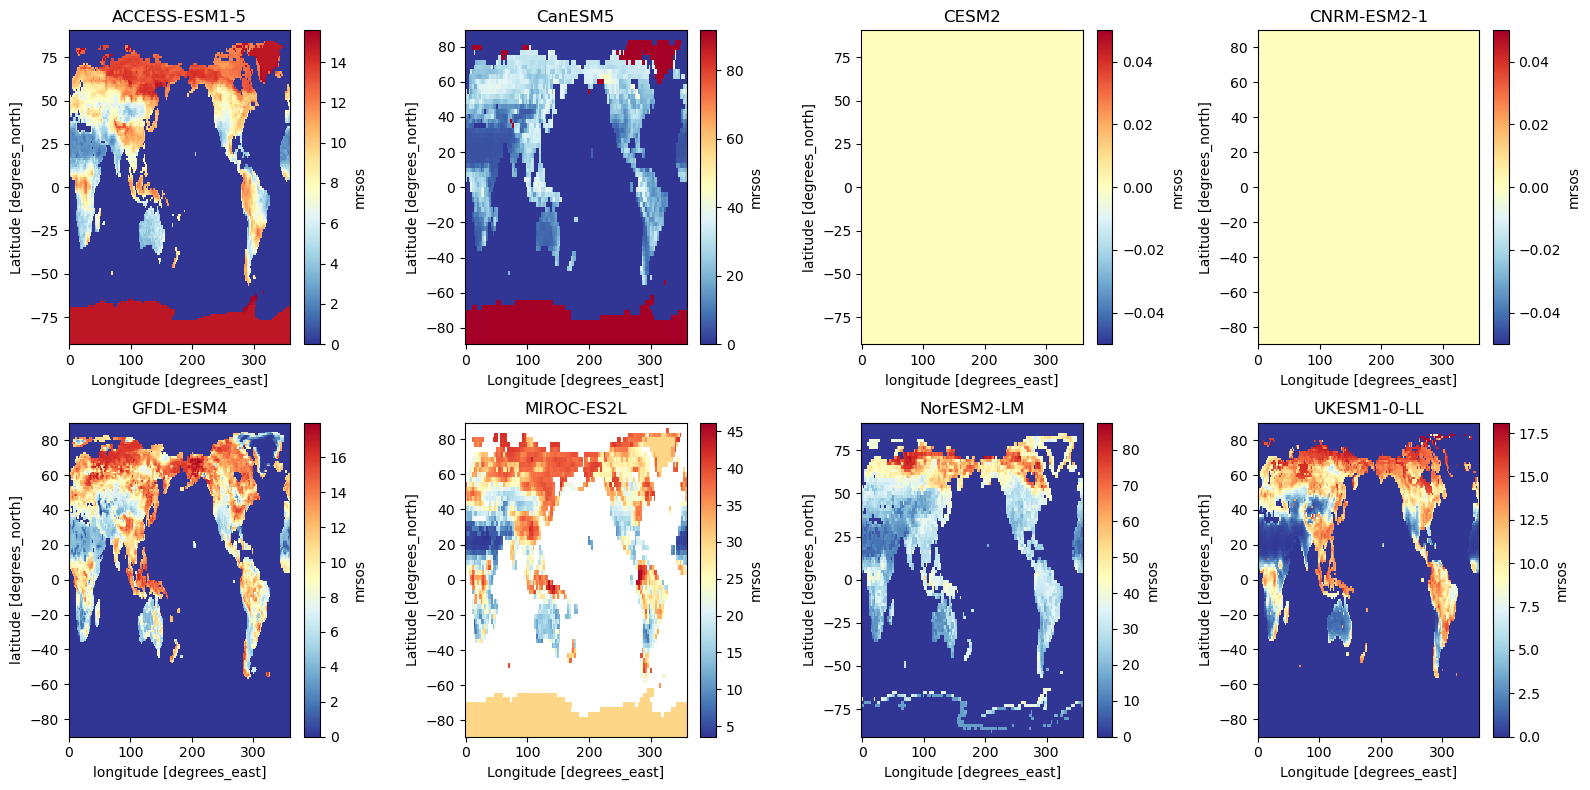

In [4]:
fig, axes = plt.subplots(2,4,figsize=(16,8))

for (model,ds), ax in zip(data.items(),axes.flat):
    
    data[model].sel(year=slice(51,71)).mean(dim='year').plot(ax=ax,cmap='RdYlBu_r')
    ax.set_title(model)
fig.tight_layout()

### Separate into gwl periods ###

In [43]:
gwl_years = load_data.load_gwl_years()

In [44]:
gwl_periods = {}
for model, ds in data.items():
    gwl_periods[model] = utils.extract_gwl_period(
        ds,
        gwl_years[model],
        21,
        time_dim='year'
    ) 

In [47]:
slices_15 = {}
gwl=1.5
for model, ds in gwl_periods.items():
    slices_15[model] = utils.compare_gwl_means(ds.sel(gwl=gwl))


In [48]:
differences_15 = {model:slices_15[model]['difference'] for model in models}
differences_15['ACCESS-ESM1-5']

<xarray.DataArray 'mrsos' (lat: 145, lon: 192)> Size: 111kB
array([[-14.807179, -14.807179, -14.807179, ..., -14.807179, -14.807179,
        -14.807179],
       [-14.807179, -14.807179, -14.807179, ..., -14.807179, -14.807179,
        -14.807179],
       [-14.807179, -14.807179, -14.807179, ..., -14.807179, -14.807179,
        -14.807179],
       ...,
       [  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
          0.      ],
       [  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
          0.      ],
       [  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
          0.      ]], dtype=float32)
Coordinates:
  * lat      (lat) float64 1kB -90.0 -88.75 -87.5 -86.25 ... 87.5 88.75 90.0
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
    gwl      float64 8B 1.5
    depth    float64 8B 0.011

## Plot ##

In [49]:
def plot_gwl_diff(to_plot,levels):

    cmap = plt.cm.RdYlBu_r.copy()
    # cmap.set_extremes(under='midnightblue',over='maroon')
          


    fig, axes = plt.subplots(2,4, subplot_kw={"projection":ccrs.Robinson()},
                         figsize=(17,6),
                         sharey=True,)

    cbar_kwargs = {"fraction": 0.02, "aspect": 20,
                    "label":"Soil Moisture Change",'orientation':'vertical',
                    'location':'right','pad':0.01,
                  'anchor':(0.5,-4), 'extend':'both'
                  }
 
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    
    for (model, da), ax in zip(to_plot.items(), axes.flat):
        im = ax.imshow(to_plot[model],
                       transform=ccrs.PlateCarree(),
                       cmap=cmap,
                       origin='lower',
                       extent=(0,360,-90,90),
                       norm=norm
                      )
        ax.set_title(model,fontsize=16)
        ax.coastlines()

    cbar_ax = fig.add_axes([1.01,0.05,0.01,0.8])
    cbar = fig.colorbar(im,
                        cax=cbar_ax,
                        **cbar_kwargs
                       )
    cbar.ax.tick_params(labelsize=14) 
    cbar.set_label("Relative Soil Moisture Difference (%)", fontsize=16)
    fig.suptitle(f"Top soil moisture difference ramp-down - ramp-up at 1.5°C GWL",
                 fontsize=25,
                 y=1.0
                )
    fig.tight_layout()
    plt.show()

In [50]:
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, CenteredNorm

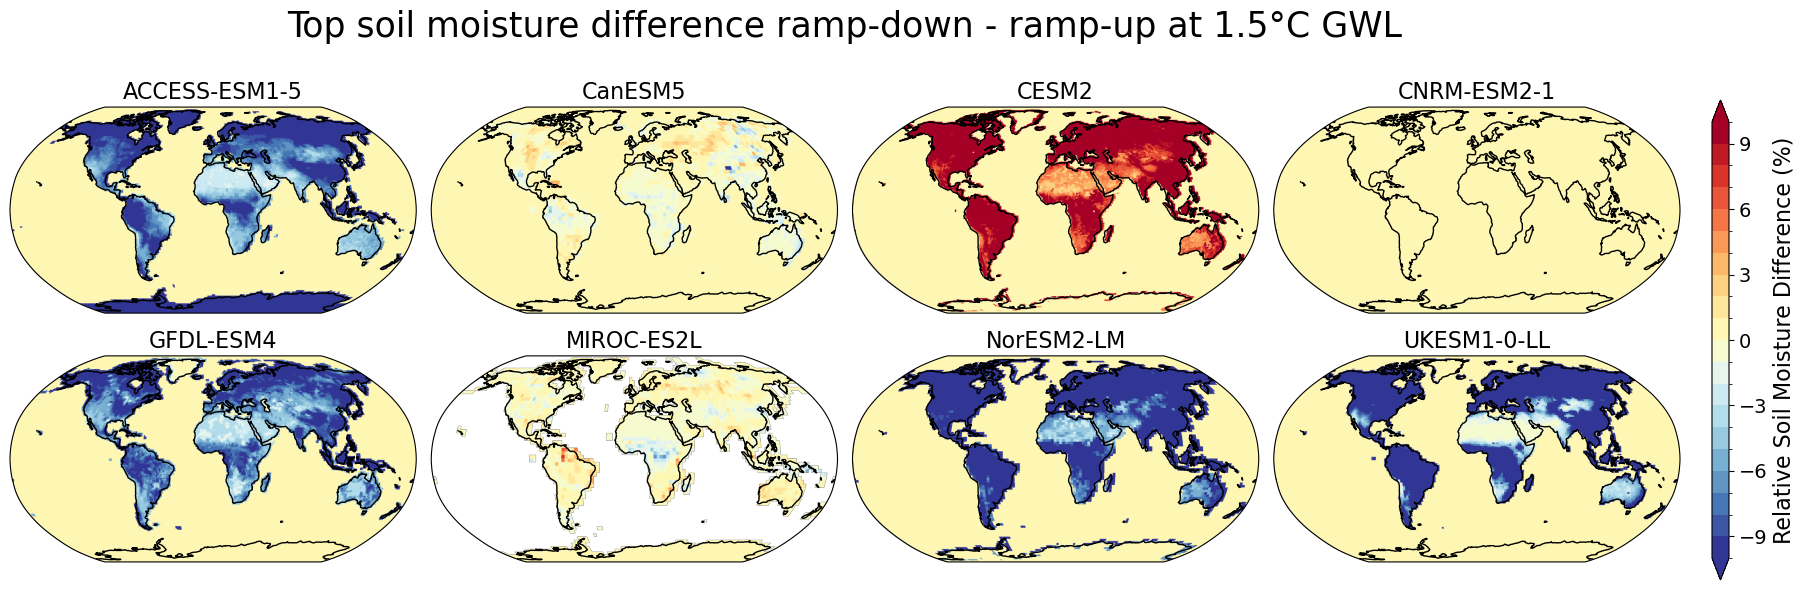

In [51]:
plot_gwl_diff(
    differences_15,
    np.linspace(-10,10,21)
)